## Color-magnitude diagram from interpolated BaSTI isochrones
***IN PROGRESS\
Esther Kwon\
Massimo Ricotti\
Department of Astronomy, University of Maryland\
Last Updated: 5/26/26

***

BaSTI isochrones provide stellar models for the absolute magnitude of stars measured through different photometric systems\
Photometric system of interest is JWST NIRcam Sirio ZP (or annotated as isc_jwst-nircam_zp_vega-sirius)

To obtain a color magnitude diagram given a cluster age, mass, lookback time/redshift, and filters of interest;\
a mass distribution, K-corrections, and AB magnitude corrections must be applied to the BaSTI isochrone to represent a \
real cluster at some distance of some age and metallicity

In [1]:
#pip install --user -r requirementsgc.txt

#### Import Statements

In [1]:
import numpy as np
import pandas as pd
import os
from imf import imf
import io
import ipywidgets as widgets
from ipyfilechooser import FileChooser
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt
from astropy import coordinates as coord
from astropy import units as u
from astropy.modeling import models
from astropy.table import Table
from astropy.io import fits

#### Docking Isochrone Bank
Select folder with all isochrones from BaSTI: http://basti-iac.oa-abruzzo.inaf.it/isocs.html 

Main values from isochrones include the age, metallicity, and the magnitude contribution from each of the 'stars' belonging to the cluster. However, the mass distribution of these 'stars'/point sources are not reflective of actual clusters and moreso show the relationship between a single point mass and its brightness (depending on age and metallicity)

In [2]:
#open folder selection UI (currently I am importing "NIRCAM Sirio ZP_zpS_Isochrones_SolarScaled")
fc = FileChooser('.')
display(fc)

FileChooser(path='C:\Users\Esther\GlobularClusterProject', filename='', title='', show_hidden=False, select_de…

In [3]:
#set selected folder as directory and iterate through isochrone files
folder = Path(fc.selected_path)
files = list(folder.glob("*.isc_jwst-nircam_zp_vega-sirius")) #open only of this file type
#for filenamename in files:
#    print(filenamename) #all paths

#### Concatenate BaSTI files
This section takes all of the exported isochrones and lists them in one single dataframe

In [4]:
#obtain all BaSTI files and concatenate them
#attatch column to dataframe to label age, metallicity, and filename

#open list to store each row
basti_rows = []

for file_path in files:
    
    filename = file_path.name

    #read file content into pandas
    file_table = Table.read(file_path, format="ascii", comment="#")
    imp_isoc = file_table.to_pandas() #dataframe consists of one isochrone

    #read headers content
    with open(file_path, mode="r") as f:
        text = f.read().splitlines()
 
    header_line = text[6]

    columnnames = header_line.lstrip("#").split()
    imp_isoc.columns = columnnames

    #extracting metallicity and age
    details = text[4].split()
    
    age = float(details[16])
    mhratio = float(details[6])

    #label the dataframe with age and metallicity
    imp_isoc["Age (Myr)"] = age
    imp_isoc["[M/H]"] = mhratio
    imp_isoc["Filename"] = filename

    basti_rows.append(imp_isoc)

#take basti rows list and merge them into one dataframe
combined_imp_isoc = pd.concat(basti_rows, ignore_index=True)

#putting age and M/H in the front
cols = list(combined_imp_isoc.columns)
cols.remove('Age (Myr)')
cols.remove('[M/H]')
cols = ['Age (Myr)','[M/H]'] + cols
combined_imp_isoc = combined_imp_isoc[cols]


display(combined_imp_isoc)


,Age (Myr),[M/H],M/Mo(ini),M/Mo(fin),log(L/Lo),logTe,F070W,F090W,F115W,F150W,...,F210M,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M,Filename
0,2000.0,-1.9,0.100000,0.100000,-2.76276,3.53173,11.5998,10.7290,10.0981,9.5108,...,9.3041,9.1971,9.0019,8.8534,8.7875,8.7264,8.7294,8.7925,8.7555,2000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_v...
1,2000.0,-1.9,0.103470,0.103470,-2.75743,3.53399,11.5720,10.7154,10.0871,9.4985,...,9.2896,9.1843,8.9926,8.8451,8.7791,8.7181,8.7218,8.7888,8.7506,2000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_v...
2,2000.0,-1.9,0.106940,0.106940,-2.76094,3.53625,11.5674,10.7233,10.0982,9.5093,...,9.2997,9.1952,9.0061,8.8602,8.7946,8.7340,8.7378,8.8083,8.7689,2000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_v...
3,2000.0,-1.9,0.110411,0.110411,-2.72863,3.54141,11.4651,10.6442,10.0261,9.4343,...,9.2146,9.1141,8.9359,8.7921,8.7267,8.6666,8.6724,8.7490,8.7088,2000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_v...
4,2000.0,-1.9,0.113881,0.113881,-2.67587,3.54786,11.3160,10.5150,9.9074,9.3122,...,9.0792,8.9836,8.8187,8.6776,8.6128,8.5537,8.5614,8.6434,8.6045,2000z0001980y247P00O1D1E1.isc_jwst-nircam_zp_v...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94495,5500.0,0.3,1.311325,1.182859,2.77124,3.57083,-1.9823,-2.9447,-3.6408,-4.4571,...,-4.9503,-4.7432,-5.0049,-5.0534,-5.0646,-5.0165,-4.9253,-4.7647,-4.8044,5500z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...
94496,5500.0,0.3,1.311331,1.182525,2.80125,3.56758,-2.0275,-3.0149,-3.7200,-4.5424,...,-5.0458,-4.8329,-5.1001,-5.1505,-5.1620,-5.1107,-5.0169,-4.8597,-4.9003,5500z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...
94497,5500.0,0.3,1.311338,1.182146,2.83311,3.56402,-2.0732,-3.0895,-3.8043,-4.6300,...,-5.1478,-4.9291,-5.2017,-5.2544,-5.2663,-5.2116,-5.1154,-4.9621,-5.0038,5500z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...
94498,5500.0,0.3,1.311344,1.181713,2.86852,3.56065,-2.1327,-3.1731,-3.8969,-4.7242,...,-5.2571,-5.0336,-5.3111,-5.3655,-5.3778,-5.3195,-5.2206,-5.0707,-5.1134,5500z0286500y284P00O1D1E1.isc_jwst-nircam_zp_v...


### Selecting Cluster Properties (redshift at observation, initial cluster mass)

In [5]:
redshift_obs = 0.87
initial_mass = 5e7

#### Defining IMF from Cluster Mass
** https://pypi.org/project/initial-mass-function/

Since the isochrones do not represent a real mass distribution, we rely instead on a Initial Mass Function generator to make the 'stars' whos masses add up to a total mass feasable and determined by the user. In the code, the mass is reduced by a factor of 100 and later multiplied back because my computer cannot handle that many 'stars'. All of the stars in the globular cluster are created at the same time.

Another restriction is that the smallest mass provided by the isochrones is 0.01 solar mass, meaning all of the smaller 'stars' in the IMF are cut off, removing some of the total mass.

Total cluster mass is 499998 (limit was 500000)
total # of point sources:  1151291
total generated cluster mass: 499998.2912649947 M_sun
scaled error =  -170.87350052595139 M_sun


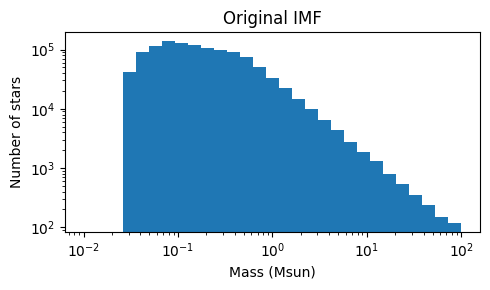

In [6]:
plt.clf()
plt.close('all') 


scalingfactor = 100 #div by 100, mass scales with lum for GC's

scaled_inimass = initial_mass/scalingfactor

#make the cluster using Kroupa IMF in make_cluster**
masses = imf.make_cluster(scaled_inimass)
#help(imf.make_cluster)
print('===============================')
print("total # of point sources: ", len(masses))
print("total generated cluster mass:", masses.sum(), 'M_sun')
print("scaled error = ", masses.sum()*scalingfactor-initial_mass, 'M_sun')
print('===============================')

#+++++++++++++++++++++++++++++++++++++++++++
#histogram of IMF
plt.figure('IMF og', figsize=(5,3))
bins = np.logspace(np.log10(0.01), np.log10(100), 30)
plt.hist(masses, bins=bins)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mass (Msun)')
plt.ylabel('Number of stars')
plt.title('Original IMF')
plt.tight_layout()

sample initial mass =  499998.2912649947 M_sun
real initial mass =  474135.1095258963 M_sun
original point source count =  1151291
cut point source count =  734759


,Initial Mass
0,0.245625
1,0.336375
2,0.107446
3,0.352384
4,0.329554
...,...
734754,1.062923
734755,0.995806
734756,0.518177
734757,1.216469


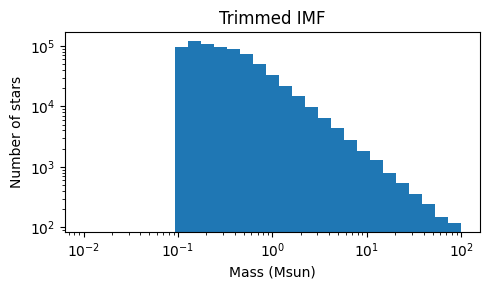

In [7]:
#trimming the IMF to exclude anything less than 0.1 solar mass
#because BaSTI isochrones do not include stars lower than 0.1 solar mass

plt.close('all') 
#-----------------------------------
print("sample initial mass = ", masses.sum(), 'M_sun')
cutmasses = masses[masses >= 0.1] #cut off masses less than 0.1 Msun
print("real initial mass = ", cutmasses.sum(), 'M_sun')
print("======================================")
print("original point source count = ", len(masses))
print("cut point source count = ", len(cutmasses))
print("======================================")

imf_points = pd.DataFrame() #putting our new IMF into a dataframe
imf_points['Initial Mass'] = cutmasses
display(imf_points)

#+++++++++++++++++++++++++++++++++++++++++++++
#histogram of trimmed IMF
plt.figure('IMF cut', figsize=(5,3))
bins = np.logspace(np.log10(0.01), np.log10(100), 30)
plt.hist(imf_points['Initial Mass'], bins=bins)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Mass (Msun)')
plt.ylabel('Number of stars')
plt.title('Trimmed IMF')
plt.tight_layout()

#### Linear Interpolation using BaSTI Isochrones
The array of masses (stars) as determined by the limited IMF has its information filled in by using the BaSTI isochrones as its reference using linear interpolation. This is done to every isochrone with x as the age and y as the magnitudes among different filters. The isochrones are isolated in this process by unique age and metallicity combinations.

In [9]:
filters = combined_imp_isoc.columns.to_numpy()[6:-1]

#----------------isochrone--------insert imf
def interpolator(refdata_subset, newdata):
    #uses the "refdata_subset" as a reference for "newdata" to be interpolated
    #newdata takes in the initial mass function points, and refdata takes in the BaSTI isochrones
    #...with information about the final mass and the filter magnitudes
    #
    #
    minmass = refdata_subset['M/Mo(ini)'].min()
    maxmass = refdata_subset['M/Mo(ini)'].max()
    newdata = newdata.loc[(newdata['Initial Mass'] <= maxmass) & (newdata['Initial Mass'] >= minmass)].copy()
    #np.interp(x_new, x_data, y_data)
    #interpolate the final masses
    finalmasses_new = np.interp(newdata['Initial Mass'].to_numpy(), refdata_subset['M/Mo(ini)'].to_numpy(), refdata_subset['M/Mo(fin)'].to_numpy())
    newdata['Final Mass'] = finalmasses_new

    #filters
    for f in filters:
        #interpolate each filter magnitude pt and add to dataframe
        filters_mag_new = np.interp(newdata['Initial Mass'].to_numpy(), refdata_subset['M/Mo(ini)'].to_numpy(), refdata_subset[f].to_numpy())
        newdata[f] = filters_mag_new

    return newdata

#-----------------------------
iterations = []

for (age, mh), isochrone_subset in combined_imp_isoc.groupby(['Age (Myr)','[M/H]']):
    #send the imf to be interpolated by the isochrones as its reference
    out = interpolator(isochrone_subset, imf_points)
    #attach age and metallicity
    out['Age (Myr)'] = age
    out['[M/H]'] = mh
    #add each to 'iterations'
    iterations.append(out)

isochrone_full = pd.concat(iterations, ignore_index=True)
display(isochrone_full)


,Initial Mass,Final Mass,F070W,F090W,F115W,F150W,F200W,F277W,F356W,F444W,...,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M,Age (Myr),[M/H]
0,0.245625,0.245625,9.182652,8.530591,8.041852,7.473427,7.168113,7.021098,6.914166,6.881156,...,7.065306,6.990595,6.934074,6.900759,6.860752,6.868956,6.906566,6.886663,2000.0,-1.9
1,0.336375,0.336375,8.478069,7.863207,7.399712,6.844758,6.547281,6.409127,6.324608,6.296132,...,6.448704,6.381939,6.340597,6.314320,6.279643,6.286332,6.315920,6.299420,2000.0,-1.9
2,0.107446,0.107446,11.552486,10.711768,10.087689,9.498366,9.315608,9.080164,8.813286,8.747640,...,9.183377,8.995866,8.850272,8.784701,8.724174,8.728265,8.799655,8.760138,2000.0,-1.9
3,0.352384,0.352384,8.365514,7.756680,7.297082,6.744147,6.448111,6.311603,6.230531,6.202877,...,6.350457,6.285048,6.245886,6.220677,6.186923,6.193350,6.221931,6.205877,2000.0,-1.9
4,0.329554,0.329554,8.525185,7.907865,7.442615,6.886860,6.588805,6.449965,6.363970,6.335200,...,6.489935,6.422580,6.380255,6.353485,6.318515,6.325215,6.355370,6.338600,2000.0,-1.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30586771,1.062923,1.062316,4.109686,3.809265,3.551141,3.190715,3.062101,3.041898,3.034996,3.052501,...,3.059805,3.034098,3.035298,3.035396,3.028596,3.042398,3.080008,3.075308,5500.0,0.3
30586772,0.995806,0.995401,4.554732,4.226432,3.939295,3.541983,3.393059,3.373827,3.361721,3.385896,...,3.398702,3.361590,3.362121,3.362021,3.355121,3.372559,3.423408,3.416440,5500.0,0.3
30586773,0.518177,0.518177,8.731485,7.545805,6.872188,6.227858,5.874632,5.848411,5.608370,5.571100,...,5.887637,5.833060,5.666643,5.562472,5.509100,5.551274,5.648900,5.625900,5500.0,0.3
30586774,1.216469,1.215044,3.215800,2.929220,2.684798,2.344029,2.224495,2.203753,2.198580,2.212311,...,2.219068,2.197580,2.198880,2.198780,2.191980,2.203753,2.234957,2.231399,5500.0,0.3


#### "Summing" Filter Magnitudes

Once the magnitudes of each 'star' in this cluster are found, we obtain the overall brightness of the entire cluster at a certain age.

This is done with the following formula:

$m_{tot}= -2.5log_{10}(scalefactor*\sum_i (10^{-\frac{M_{infilter}}{2.5}}))$
-
where scalefactor is multiplying the sum of luminosities by how much the mass was decreased prior.\
In the code is operation is performed on isochrones in the dataframe where age and metallicity are equivalent across rows.

In [10]:
def magnitudesum(dataframe, filtername):
    #converts each individual magnitude into a luminosity,
    #then sums up all the luminosity points
    #multiplies the total luminosity by the scaling factor (M propto L)
    #then converts back into magnitudes
    magsinfilter = dataframe[filtername].to_numpy()
    magsintolums = 10**(-magsinfilter/2.5)
    totallums = magsintolums.sum()
    rescaledtotallums = totallums*scalingfactor
    totalmags = -2.5*np.log10(rescaledtotallums)
    #print(totallums)
    return totalmags

#-----------------------------
masses_sums_list = []
filtermags_sums_list = []

filternames = isochrone_full.columns.to_numpy()[2:-2]
#print(filternames)

#loop isolates each isochrone (sets of points where age and metallicity are the same)
#Then sends an individual isochrone to the magnitude sum function to be "summed"
#appends to list of the summed magnitudes
for (age, mhratio), single_isoc in isochrone_full.groupby(['Age (Myr)', '[M/H]']):

    #print(group)
    #Summing initial and final masses
    #totalmassinitial = single_isoc['Initial Mass'].sum()*scalingfactor
    totalmassfinal = single_isoc['Final Mass'].sum()*scalingfactor
    #totalmassloss = totalmassinitial-totalmassfinal
    
    masses_sums_list.append({
        #"Total Mass (ini)": totalmassinitial,
        "Total Mass (fin)": totalmassfinal,
        #"Total Mass Loss": totalmassloss
    })

    #grab only filter columns of the dataframe
    filter_values = single_isoc[filternames]
    row = {'Age (Myr)': age, '[M/H]': mhratio}
    
    #summing up the magnitudes
    for filtername in filternames:
        #run through magnitude sums function
        row[filtername] = magnitudesum(filter_values, filtername)
    #print(row)

    filtermags_sums_list.append(row)

masses_sums = pd.DataFrame(masses_sums_list)
filtermags_sums = pd.DataFrame(filtermags_sums_list)

allsums = pd.concat([masses_sums, filtermags_sums], axis=1)
allsums = allsums.loc[:, allsums.columns.notna() & (allsums.columns != "")] #remove nan and empty values

allsums = allsums.sort_values(by=['Age (Myr)', '[M/H]'], ascending=[True, True])

display(allsums)

,Total Mass (fin),Age (Myr),[M/H],F070W,F090W,F115W,F150W,F200W,F277W,F356W,...,F182M,F210M,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M
0,2.388170e+07,2000.0,-1.90,-14.841553,-15.169919,-15.454057,-15.876517,-16.053316,-16.093240,-16.110507,...,-16.049026,-16.059370,-16.078399,-16.099804,-16.106445,-16.112782,-16.124422,-16.120114,-16.110593,-16.111626
1,2.601364e+07,2000.0,0.15,-14.453764,-14.922541,-15.353161,-15.932023,-16.246660,-16.238239,-16.335025,...,-16.234874,-16.259511,-16.148504,-16.302369,-16.329312,-16.339079,-16.330152,-16.280912,-16.156299,-16.178527
2,2.623806e+07,2000.0,0.30,-14.379814,-14.867369,-15.310666,-15.890138,-16.215969,-16.205829,-16.311153,...,-16.202255,-16.230358,-16.111443,-16.275114,-16.305382,-16.315387,-16.300906,-16.246282,-16.121043,-16.145303
3,2.351393e+07,2250.0,-1.90,-14.750101,-15.080765,-15.366021,-15.788681,-15.964888,-16.005042,-16.022376,...,-15.960557,-15.970997,-15.990286,-16.011561,-16.018282,-16.024669,-16.036378,-16.032296,-16.023509,-16.024372
4,2.562275e+07,2250.0,0.15,-14.330843,-14.816449,-15.258673,-15.850149,-16.175600,-16.166925,-16.267363,...,-16.163194,-16.188977,-16.073669,-16.232590,-16.261306,-16.271679,-16.261025,-16.209875,-16.084912,-16.108118
5,2.585367e+07,2250.0,0.30,-14.261972,-14.758385,-15.206602,-15.790164,-16.115894,-16.106771,-16.211978,...,-16.102239,-16.130351,-16.012485,-16.175761,-16.205945,-16.216348,-16.203925,-16.150581,-16.025134,-16.049183
6,2.317825e+07,2500.0,-1.90,-14.683000,-15.022910,-15.315341,-15.747180,-15.927804,-15.968679,-15.986835,...,-15.923250,-15.934151,-15.953113,-15.975701,-15.982647,-15.989183,-16.001057,-15.996431,-15.985456,-15.986796
7,2.530777e+07,2500.0,0.15,-14.234427,-14.739509,-15.194712,-15.799888,-16.138578,-16.128827,-16.234569,...,-16.125317,-16.152621,-16.030860,-16.197259,-16.228168,-16.239194,-16.226146,-16.172832,-16.049012,-16.073325
8,2.551835e+07,2500.0,0.30,-14.139790,-14.673990,-15.145303,-15.745229,-16.098490,-16.088254,-16.207024,...,-16.082573,-16.114593,-15.982907,-16.165016,-16.200120,-16.212079,-16.199397,-16.147734,-16.035719,-16.060180
9,2.287436e+07,2750.0,-1.90,-14.605445,-14.949597,-15.245211,-15.680802,-15.863393,-15.904810,-15.923469,...,-15.858675,-15.869898,-15.888860,-15.912092,-15.919211,-15.925862,-15.937855,-15.932950,-15.920887,-15.922505


### CMD Plotting Function (declare variables to show)

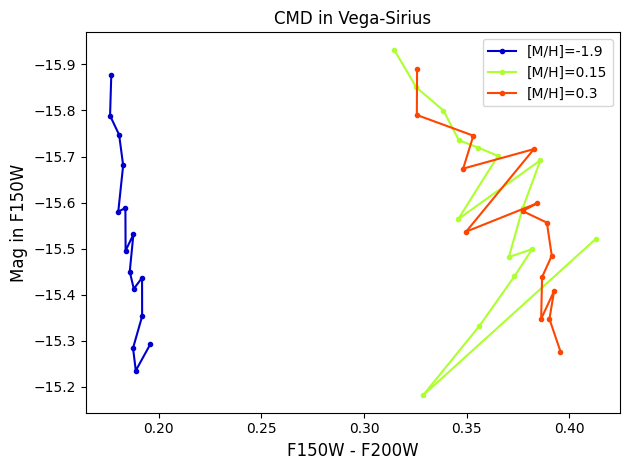

In [20]:
#var declare
#--------------
filts_color = ['F150W', 'F200W']
#ages_plot = np.arange(2000, 11000, 1000)
mlicitys_plot = [-1.90, 0.15, 0.30]
#--------------

def CMDplot(title, table, twofilts, mlicitys):
    filtcolor1 = twofilts[0]
    filtcolor2 = twofilts[1]
    
    plt.figure("CMD", clear=True)
    plt.title(title)
    plt.xlabel(f"{filtcolor1} - {filtcolor2}", fontsize=12)
    plt.ylabel(f"Mag in {filtcolor1}", fontsize=12)

    colcode = ["mediumblue", "greenyellow", "orangered"]
    g = table
    
    for i in range(len(mlicitys)):
        plt.plot(g.loc[g["[M/H]"] == mlicitys[i], filtcolor1] - g.loc[g["[M/H]"] == mlicitys[i], filtcolor2], g.loc[g["[M/H]"] == mlicitys[i], filtcolor1], ".-", label=f"[M/H]={mlicitys[i]}", color=colcode[i])

    plt.legend()
    plt.tight_layout()
    ax = plt.gca() # Get current axes
    ax.invert_yaxis()

    plt.show()

#plotting statement

CMDplot('CMD in Vega-Sirius', allsums, filts_color, mlicitys_plot)

#### AB corrections
$M_{AB} = M_{absolute,Vega-Sirius} + conv_{Vega, AB}$\
$conv_{Vega,AB} = ZP_{AB} - ZP_{Vega-Sirius} - 2.5log_{10}(PHOTMJSR)$\
Derived from equations mentioned at: https://jwst-docs.stsci.edu/jwst-near-infrared-camera/nircam-performance/nircam-absolute-flux-calibration-and-zeropoints#gsc.tab=0

AB details and provided here: (add parent link)
https://jwst-docs.stsci.edu/files/216457093/216457096/1/1762453608965/NRC_ZPs_1126pmap.txt \
The mean of each filter's AB correction per each CCD is added to the corresponding filter

Index([' pupil+filter ', '      sca ', ' PHOTMJSR ', ' zp_vega ', '  vega_Jy ',
       ' zp_vega-sirius ', ' vega-sirius_Jy ', ' zp_AB ', ' mean_pix_sr '],
      dtype='object')
['F070W' 'F090W' 'F115W' 'F150W' 'F200W' 'F277W' 'F356W' 'F444W' 'F150W2'
 'F322W2' 'F140M' 'F162M' 'F182M' 'F210M' 'F250M' 'F300M' 'F335M' 'F360M'
 'F410M' 'F430M' 'F460M' 'F480M']


,index,conv(Vega to AB)
0,F070W,0.233346
1,F090W,0.485512
2,F115W,0.765371
3,F150W,1.205526
4,F200W,1.687174
5,F277W,2.322087
6,F356W,2.811348
7,F444W,3.238000
8,F140M,1.099317
9,F182M,1.569256


,Total Mass (fin),Age (Myr),[M/H],F070W,F090W,F115W,F150W,F200W,F277W,F356W,...,F182M,F210M,F250M,F300M,F335M,F360M,F410M,F430M,F460M,F480M
0,2.388170e+07,2000.0,-1.90,-14.608207,-14.684408,-14.688686,-14.670992,-14.366142,-13.771154,-13.299158,...,-14.479770,-14.267898,-13.944113,-13.618524,-13.399308,-13.255398,-13.025954,-12.920492,-12.745130,-12.678072
1,2.601364e+07,2000.0,0.15,-14.220418,-14.437029,-14.587790,-14.726498,-14.559485,-13.916152,-13.523677,...,-14.665618,-14.468038,-14.014217,-13.821089,-13.622175,-13.481694,-13.231684,-13.081291,-12.790836,-12.744974
2,2.623806e+07,2000.0,0.30,-14.146468,-14.381857,-14.545295,-14.684613,-14.528794,-13.883742,-13.499805,...,-14.632999,-14.438885,-13.977157,-13.793834,-13.598245,-13.458003,-13.202438,-13.046661,-12.755580,-12.711749
3,2.351393e+07,2250.0,-1.90,-14.516755,-14.595253,-14.600650,-14.583156,-14.277714,-13.682956,-13.211028,...,-14.391301,-14.179525,-13.856000,-13.530281,-13.311145,-13.167284,-12.937910,-12.832674,-12.658046,-12.590818
4,2.562275e+07,2250.0,0.15,-14.097497,-14.330937,-14.493303,-14.644624,-14.488426,-13.844839,-13.456014,...,-14.593938,-14.397504,-13.939383,-13.751310,-13.554169,-13.414294,-13.162557,-13.010253,-12.719449,-12.674564
5,2.585367e+07,2250.0,0.30,-14.028626,-14.272873,-14.441231,-14.584639,-14.428720,-13.784684,-13.400630,...,-14.532983,-14.338878,-13.878198,-13.694481,-13.498808,-13.358963,-13.105457,-12.950960,-12.659671,-12.615630
6,2.317825e+07,2500.0,-1.90,-14.449654,-14.537398,-14.549971,-14.541655,-14.240630,-13.646593,-13.175487,...,-14.353994,-14.142679,-13.818827,-13.494421,-13.275510,-13.131798,-12.902589,-12.796810,-12.619993,-12.553242
7,2.530777e+07,2500.0,0.15,-14.001081,-14.253997,-14.429342,-14.594362,-14.451403,-13.806740,-13.423221,...,-14.556061,-14.361148,-13.896573,-13.715979,-13.521031,-13.381810,-13.127678,-12.973210,-12.683549,-12.639772
8,2.551835e+07,2500.0,0.30,-13.906443,-14.188478,-14.379933,-14.539703,-14.411316,-13.766168,-13.395675,...,-14.513317,-14.323121,-13.848620,-13.683736,-13.492983,-13.354695,-13.100929,-12.948112,-12.670256,-12.626626
9,2.287436e+07,2750.0,-1.90,-14.372098,-14.464085,-14.479840,-14.475276,-14.176219,-13.582723,-13.112121,...,-14.289419,-14.078426,-13.754574,-13.430811,-13.212074,-13.068478,-12.839387,-12.733328,-12.555424,-12.488952


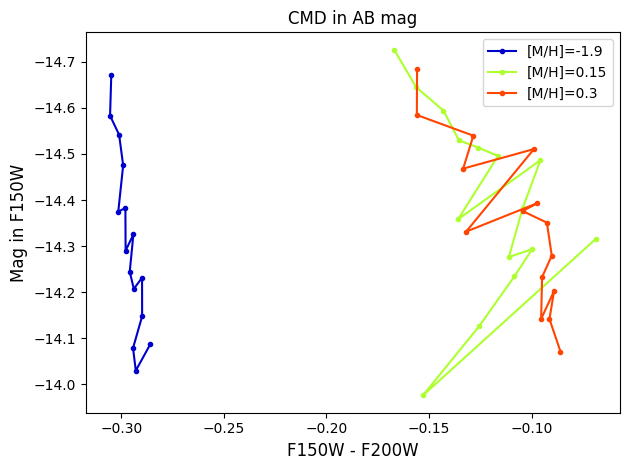

In [15]:
#m_AB=m_Vega-sirius + conversion_factor.

#importing table with ZP's and PHOTMJSR
ZPtable = pd.read_csv('NRC_ZPs_1126pmap.txt', sep='|', header=4)
print(ZPtable.columns[1:-1])

PHOTMJSR = ZPtable[' PHOTMJSR ']
pupil_filter = ZPtable[' pupil+filter ']
ZP_vega_sirius = ZPtable[' zp_vega-sirius ']
ZP_AB = ZPtable[' zp_AB ']
conv_Vega_to_AB = (ZP_AB-ZP_vega_sirius-2.5*np.log10(PHOTMJSR))
"""#was printing table contents here
for i in range(len(filter)):
    print(f'{pupil_filter[i]}, {conv_Vega_AB[i]:.3f}')
"""
conversions_filters = pd.DataFrame({'conv(Vega to AB)': conv_Vega_to_AB})
ABconversions = pd.concat([pupil_filter, conversions_filters], axis=1)
#avg over where the filternames are the same
meanABconversions = ABconversions.groupby(' pupil+filter ', as_index=False)['conv(Vega to AB)'].mean()
meanABconversions[' pupil+filter '] = (meanABconversions[' pupil+filter '].str.strip()) #remove spaces
#display(meanABconversions)

#isolating last 5 digits of filter name, then keeping only relevant filters (what equals the column names of isochrone array
ABconversions_renamed = meanABconversions.copy()
ABconversions_renamed[' pupil+filter '] = meanABconversions[' pupil+filter '].str[-5:]
ABconversions_for_isoc = ABconversions_renamed[ABconversions_renamed[' pupil+filter '].isin(filters)][:-3] #last 3 are dupes
print(filters)
#display(ABconversions_for_isoc)

#remove columns in allsums without AB corrections
filts_to_include = ABconversions_for_isoc[' pupil+filter '].values
AB_cut_isoc = allsums.copy()
AB_cut_isoc = allsums.iloc[:, :3].join(allsums.iloc[:, 3:].loc[:, allsums.columns[3:].isin(filts_to_include)])
#display(AB_cut_isoc)
#reorder ABconversions to match isochrone
ABconversions_for_isoc = (ABconversions_for_isoc.set_index(' pupil+filter ').reindex(AB_cut_isoc.columns[3:]).reset_index())
display(ABconversions_for_isoc)

#now add value in column 'conv' to all rows of column where column = value in pupil+filter
AB_corrected_isoc = AB_cut_isoc.copy()
for filt in AB_cut_isoc.columns[3:]:
    AB_corrected_isoc[filt] = (allsums[filt] + ABconversions_for_isoc.loc[ABconversions_for_isoc['index'] == filt, 'conv(Vega to AB)'].iloc[0])

display(AB_corrected_isoc)

#plotting after AB corrections
CMDplot('CMD in AB mag', AB_corrected_isoc, filts_color, mlicitys_plot)

#### K corrections
K corrections from Reina-Campos and Harris: https://arxiv.org/pdf/2310.02307 \

K correction files found at: https://zenodo.org/records/8387817

\
$M_{absolute,restframe} = m_{observed, in filter} - 5log_{10}(\frac{distance}{10pc}) - K_{correction}$
\
$M_{absolute,restframe} = M_{absolute,infilter} - K_{correction}$

K corrections are intended to convert the magnitudes in each filter into what they are in their rest frame.

A redshift at observation and age of cluster is used to pick out the right K-corrections as follows: at an observed redshift of __ it is __ years old.\
The values we want to input are the age of the cluster as measured from Earth, which here depends on the redshift\
$age_{Earth} = lookbacktime(z) + age at z$

Other values of interest are the z at creation and the time of creation since BB.

,z,[M/H],Age,K corr. F070W,K corr. F090W,K corr. F115W,K corr. F150W,K corr. F200W,K corr. F277W,K corr. F356W
1,0.875,-1.79,T01,0.313708,-0.201553,-0.318281,-0.458081,-0.642301,-1.404797,-1.658394
9,0.875,0.15,T01,0.696370,-0.057210,-0.168318,-0.255682,-0.624635,-1.334574,-1.612808
10,0.875,0.26,T01,0.729180,-0.055593,-0.183771,-0.256908,-0.597895,-1.330728,-1.613119
13,0.875,-1.79,T02,0.442754,-0.144457,-0.354097,-0.529650,-0.756334,-1.443987,-1.684732
21,0.875,0.15,T02,1.216980,0.358300,0.107694,-0.070798,-0.466154,-1.317927,-1.651171
22,0.875,0.26,T02,1.248854,0.371530,0.121853,-0.050102,-0.445563,-1.311717,-1.641108
25,0.875,-1.79,T03,0.481332,-0.100309,-0.350337,-0.546651,-0.792667,-1.458638,-1.690001
33,0.875,0.15,T03,1.390601,0.467457,0.179414,-0.027259,-0.439406,-1.308127,-1.651191
34,0.875,0.26,T03,1.459806,0.527310,0.247375,0.035207,-0.417510,-1.317108,-1.655992
37,0.875,-1.79,T04,0.571838,-0.052099,-0.331905,-0.548756,-0.811321,-1.464079,-1.691179


['F070W', 'F090W', 'F115W', 'F150W', 'F200W', 'F277W', 'F356W']


,Total Mass (fin),Age (Myr),[M/H],F070W,F090W,F115W,F150W,F200W,F277W,F356W
0,2.388170e+07,2000.0,-1.90,-14.608207,-14.684408,-14.688686,-14.670992,-14.366142,-13.771154,-13.299158
1,2.601364e+07,2000.0,0.15,-14.220418,-14.437029,-14.587790,-14.726498,-14.559485,-13.916152,-13.523677
2,2.623806e+07,2000.0,0.30,-14.146468,-14.381857,-14.545295,-14.684613,-14.528794,-13.883742,-13.499805
3,2.351393e+07,2250.0,-1.90,-14.516755,-14.595253,-14.600650,-14.583156,-14.277714,-13.682956,-13.211028
4,2.562275e+07,2250.0,0.15,-14.097497,-14.330937,-14.493303,-14.644624,-14.488426,-13.844839,-13.456014
5,2.585367e+07,2250.0,0.30,-14.028626,-14.272873,-14.441231,-14.584639,-14.428720,-13.784684,-13.400630
6,2.317825e+07,2500.0,-1.90,-14.449654,-14.537398,-14.549971,-14.541655,-14.240630,-13.646593,-13.175487
7,2.530777e+07,2500.0,0.15,-14.001081,-14.253997,-14.429342,-14.594362,-14.451403,-13.806740,-13.423221
8,2.551835e+07,2500.0,0.30,-13.906443,-14.188478,-14.379933,-14.539703,-14.411316,-13.766168,-13.395675
9,2.287436e+07,2750.0,-1.90,-14.372098,-14.464085,-14.479840,-14.475276,-14.176219,-13.582723,-13.112121


,Total Mass (fin),Age (Myr),[M/H],F070W,F090W,F115W,F150W,F200W,F277W,F356W
0,2.388170e+07,2000.0,-1.90,-15.050961,-14.539951,-14.334589,-14.141342,-13.609807,-12.327167,-11.614427
1,2.601364e+07,2000.0,0.15,-15.437397,-14.795329,-14.695484,-14.655699,-14.093332,-12.598225,-11.872506
2,2.623806e+07,2000.0,0.30,-15.395322,-14.753387,-14.667148,-14.634511,-14.083231,-12.572025,-11.858697
3,2.351393e+07,2250.0,-1.90,-14.959509,-14.450796,-14.246553,-14.053506,-13.521379,-12.238969,-11.526296
4,2.562275e+07,2250.0,0.15,-15.314477,-14.689236,-14.600997,-14.573826,-14.022272,-12.526911,-11.804844
5,2.585367e+07,2250.0,0.30,-15.277480,-14.644403,-14.563084,-14.534537,-13.983157,-12.472967,-11.759522
6,2.317825e+07,2500.0,-1.90,-14.892408,-14.392941,-14.195873,-14.012005,-13.484296,-12.202606,-11.490755
7,2.530777e+07,2500.0,0.15,-15.218061,-14.612297,-14.537036,-14.523564,-13.985250,-12.488813,-11.772050
8,2.551835e+07,2500.0,0.30,-15.155297,-14.560008,-14.501786,-14.489601,-13.965753,-12.454451,-11.754568
9,2.287436e+07,2750.0,-1.90,-14.853430,-14.363776,-14.129503,-13.928625,-13.383552,-12.124085,-11.422119


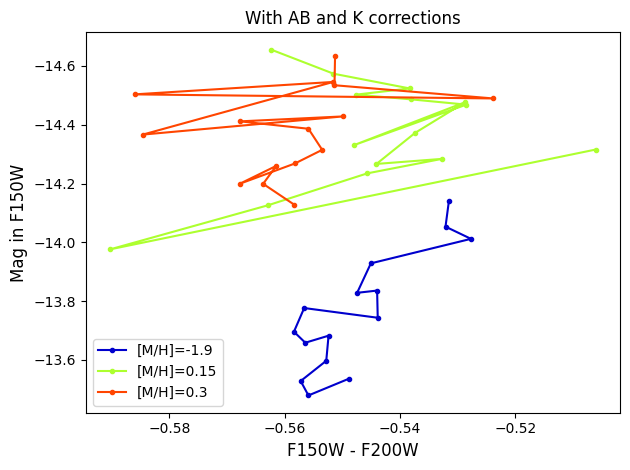

In [24]:
z = redshift_obs

#to get the kcorrection i neeed to import the files, then use ageatz= age -  lookback time to grab age at time and z val from file
# turn all -100 to NaN
# remove all upper and lower uncertainty not necessary rn i think
# just import the relevant row for closest z

Kcorr_folder = Path(r"K_corrections\\homo")
Kcorr_files = list(Kcorr_folder.glob("*.csv")) #open only of this file type

unique_metallicities = np.sort(AB_corrected_isoc['[M/H]'].unique())
#print(unique_metallicities)

K_filts = []
Kcorr_table = pd.DataFrame()

for file_path in Kcorr_files:
    
    filename = file_path.name

    #extract filtername
    filenamesplit = filename.split("_")
    filtername = filenamesplit[7]
    K_filts.append(filtername)
    
    #read file content into pandas
    z_line = pd.read_csv(file_path, index_col=0)
    nearest_z_idx = (z_line['z'] - z).abs().idxmin()
    z_line = z_line.loc[[nearest_z_idx]]

    z_line['filter'] = filtername

    z_line = z_line[['z'] + [col for col in z_line.columns[1:] if col.endswith('_target')]]
    z_line = z_line.reset_index(drop=True)
    #display(z_line)
    
    #turning the single line into a table with columns z, [M/H], age, and K correction
    K_table_per_filter = []
    
    #etract metallicity, age, and K correction from each column
    for col in z_line.columns[1:]:
        metallicity_str = col.split('Z')[1].split('T')[0]
        metallicity_flt = float(metallicity_str.replace('p', '').replace('m', '-'))
        age = 'T' + col.split('T')[1][:2]
        k_correction = z_line[col].iloc[0]
    
        K_table_per_filter.append({
            'z': z_line['z'].iloc[0],
            '[M/H]': metallicity_flt,
            'Age': age,
            'K correction': k_correction
        })
    
    
    # Convert to DataFrame
    K_table_full = pd.DataFrame(K_table_per_filter)
    
    
    # Set the column order
    K_table_full = K_table_full[['z', '[M/H]', 'Age', 'K correction']]
    
    #remove all rows that arent relevant metallicities
    closest_metallicities = [
        K_table_full['[M/H]'].iloc[
            np.abs(K_table_full['[M/H]'] - m).argmin()
        ]
        for m in unique_metallicities
    ]
    
    K_table_cut = K_table_full[
        K_table_full['[M/H]'].isin(closest_metallicities)
    ]
    
    #display(K_table_cut)

    if Kcorr_table.empty:
        Kcorr_table['z'] = K_table_cut['z']
        Kcorr_table['[M/H]'] = K_table_cut['[M/H]']
        Kcorr_table['Age'] = K_table_cut['Age']

    Kcorr_table[f'K corr. {filtername}'] = K_table_cut['K correction']
    

display(Kcorr_table)
    
#retrive AB corrected dataframe and create a copy without filters not present in K corrections
print(K_filts)
K_cut_isoc = AB_corrected_isoc.iloc[:, :3].join(AB_corrected_isoc.iloc[:, 3:].loc[:, AB_corrected_isoc.columns[3:].isin(K_filts)])
display(K_cut_isoc)

#Apply K corrections from Kcorr_table to K_cut_isoc
K_corrected_isoc = K_cut_isoc.copy()
#there are -100 rows that are no longer physically possible.
rows_to_remove = set()

for (age, mhratio), fullrow in K_corrected_isoc.groupby(['Age (Myr)', '[M/H]']):
    for filts in K_filts:
        #obtaining age to pull from Kcorr_table
        Kage = Kcorr_table['Age'].iloc[(Kcorr_table['Age'].str[1:].astype(int) * 1000 - age).abs().argmin()]
        #obtaining closest metallicity to pull from Kcorr_table
        Kmlicity = Kcorr_table['[M/H]'].iloc[np.abs(Kcorr_table['[M/H]'] - mhratio).argmin()]
        
        #using Kage and Kmlicity to grab and correct right value
        Kcorr = Kcorr_table.loc[(Kcorr_table['Age'] == Kage) & (Kcorr_table['[M/H]'] == Kmlicity), f'K corr. {filts}'].iloc[0]

        #removing rows with K corrections -100
        if np.isclose(Kcorr, -100):
            rows_to_remove.update(fullrow.index)
        
        K_corrected_isoc.loc[fullrow.index, filts] -= Kcorr

K_corrected_isoc = K_corrected_isoc.drop(index=rows_to_remove)
display(K_corrected_isoc)

#plotting K corrected
CMDplot('With AB and K corrections', K_corrected_isoc, filts_color, mlicitys_plot)